# A near-term rainfall projection from CMIP6

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/sources/cmip6_rx1day_projection.ipynb) · [GitHub preview](https://github.com/RiskThinking/crc-docs/blob/main/notebooks/sources/cmip6_rx1day_projection.ipynb)

**crc-sdk** canonicalizes gridded climate sources into the same H3 hazard
curves as JRC floods or ERA5. This notebook pulls **CMIP6** daily precipitation
straight from the
[AWS Open Data registry](https://registry.opendata.aws/cmip6/) (the Pangeo Zarr
mirror, `s3://cmip6-pds`, anonymous) and builds an **Rx1day** baseline for the
US Pacific Northwest from one model, one pathway, one decade:

- **Rx1day**, the wettest day of each year (annual maximum one-day precipitation),
- **GFDL-ESM4**, scenario **ssp585**, member **r1i1p1f1**, **2015-2024**.

1. **Plan** -- a lazy, cacheable `HazardDataset.cmip6(...)` plan: recipe, model,
   pathway, member, area and years. The Pangeo catalogue lookup happens later.
2. **Hazard** -- reduce 10 years of daily precip to 10 *annual maxima per cell*
   and fit a GEV curve per cell with the CRC engine.
3. **Assets** -- read return levels (1-in-2, 1-in-5, 1-in-10) for five cities.
4. **Look closer** -- the 10 annual values behind a wet and a dry curve, and a
   map of the 10-year level that tiles the whole region.

The result is an ordinary canonical dataset, so the portfolio evaluator works
unchanged, and the same recipe name (`rx1day`) also works for ERA5.

**Workflow:** [Setup and tested versions](https://github.com/RiskThinking/crc-docs/blob/main/ai-playbooks/docs/setup.md) · [All problems](https://github.com/RiskThinking/crc-docs/blob/main/README.md#choose-a-problem)

## Run the notebook

In Colab, choose **Runtime → Run all**. The setup cell installs the required
packages; the first data read streams ~1 GB of daily precip from S3 and takes a
few minutes, then reduces it to annual maxima. Later runs reuse the cache.

In [1]:
#@title Install dependencies and prepare this notebook
import importlib.metadata
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

if sys.version_info < (3, 12):
    raise RuntimeError("Use a Python 3.12+ runtime (Colab: Runtime > Change runtime type).")

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           "--disable-pip-version-check", "crc-sdk[geometry,zarr]>=0.11.1,<1", "plotly>=6", "nbformat>=5.10"])
    importlib.invalidate_caches()
print(f"crc-sdk {importlib.metadata.version('crc-sdk')} ready. Run the remaining cells in order.")


crc-sdk 0.11.1 ready. Run the remaining cells in order.


In [2]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow as pa
import pyarrow.parquet as pq
from shapely.geometry import mapping

from crc_sdk.connectors import read_hazard_dataset
from crc_sdk.connectors.blocks import plotting_position_curve
from crc_sdk.geometry import cell_polygon
from crc_sdk.workflows import (
    BlockExtremaPolicy,
    HazardDataset,
    curve_quantiles_at,
    return_periods_to_probabilities,
)

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000
pio.defaults.default_height = 470

DATA_DIR = Path("../data/cmip6_rx1day_projection")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# CI runs the same code path. The request is already small (one model, one box,
# ten years), so there is nothing to shrink; the flag is kept for consistency.
CI = os.environ.get("CRC_DOCS_CI") == "1"

# One model, one pathway, one member, one decade. The Pacific Northwest box.
MODEL, SCENARIO, MEMBER = "GFDL-ESM4", "ssp585", "r1i1p1f1"
BOUNDS = (-125.0, 42.0, -116.0, 49.0)  # W, S, E, N
YEARS = (2015, 2024)
# GFDL-ESM4 is a ~1 x 1.25 degree grid; H3 r4 cells are finer, so each source
# cell is expanded onto the H3 cells it covers and the region is densely tiled.
H3_RES = 4
RETURN_PERIODS = [2, 5, 10]
CITIES = {
    "Seattle": (-122.33, 47.61), "Portland": (-122.68, 45.52),
    "Eugene": (-123.09, 44.05), "Spokane": (-117.43, 47.66),
    "Boise": (-116.20, 43.62),
}


## 1. Plan: one dataset from the catalogue

`HazardDataset.cmip6(recipe, model=, scenario=, member=)` is the same immutable,
lazy builder as the ERA5 and JRC workflows. `rx1day` is the annual maximum
one-day precipitation, in mm/day. At materialization the Pangeo CMIP6 catalogue
(`s3://cmip6-pds`) is searched for the one daily precipitation Zarr store that
matches the model, experiment and member, and only the requested area and years
are read. `explain()` makes no network request.


In [3]:
plan = (
    HazardDataset.cmip6("rx1day", model=MODEL, scenario=SCENARIO, member=MEMBER)
    .for_area(BOUNDS)
    .years(*YEARS)
    .cache(DATA_DIR / "cache", mode="reuse")
    .canonicalize(policy=BlockExtremaPolicy.curated(
        h3_resolution=H3_RES, minimum_years=10, minimum_return_value=0,
    ))
)
print(plan.explain())


Recipe: rx1day (annual maximum one-day precipitation total, mm/day)
Dataset: GFDL-ESM4 ssp585 r1i1p1f1 day pr -> CMIP6.ScenarioMIP.NOAA-GFDL.GFDL-ESM4.ssp585.r1i1p1f1.day.pr.gr1.v20180701
Archive: aws (CMIP6 on the AWS Open Data registry (s3://cmip6-pds), Pangeo Zarr mirror, anonymous)
Area: -125.0,42.0,-116.0,49.0
Years: 2015-2024 (10); 10 cached, 0 to fetch
Cache: reuse (../data/cmip6_rx1day_projection/cache)
Tail: upper; ensemble: single_member
Licence: CC-BY-SA-4.0
Fit: genextreme, sample_lmoments
Catalogue lookup, network access and fitting occur only at prefetch/materialize/write.


## 2. Hazard: annual maxima, fitted per H3 cell

`materialize()` reduces the selected years of daily precipitation to one annual
maximum per model grid cell (ten values each), places each cell's maxima on the
H3 cells it covers and fits a GEV curve (sample L-moments) per cell. Rainfall is
bounded below at 0 (`minimum_return_value`), and the short ten-year record is
allowed explicitly with `minimum_years=10`; the default is 20. The canonical
file carries licence, window and ensemble. GFDL publishes CC BY-SA 4.0, which
goes beyond attribution, so the SDK warns and records it.


In [4]:
rx = plan.materialize(DATA_DIR / "cmip6_pnw_rx1day.parquet")
result = rx.materialization
print(f"{result.canonical_rows:,} canonical rows; "
      f"{result.source_cache_hits} cached years read, {result.source_cache_misses} fetched")
meta = rx.metadata()
pd.Series({
    "source": meta.source.dataset, "licence": meta.source.licence,
    "store": meta.source.uri,
    "window": f"{meta.temporal_window.start_year}-{meta.temporal_window.end_year}",
    "calendar": meta.temporal_window.calendar,
    "ensemble": f"{meta.ensemble.pooling} ({', '.join(meta.ensemble.models)}, {SCENARIO})",
    "fit": f"{', '.join(meta.fitting.families)}, {meta.fitting.method}",
    "return periods supported": (tuple(round(v, 1) for v in meta.return_period_support)
                                 if meta.return_period_support else "fit range"),
}, name="Rx1day metadata")


1,106 canonical rows; 10 cached years read, 0 fetched


/Users/woozyking/rtai/crc-docs/.venv/lib/python3.12/site-packages/crc_sdk/workflows/_plans.py:213: RestrictiveLicenceWarning: GFDL-ESM4 ssp585 r1i1p1f1 day pr (gr1, v20180701) is published under CC-BY-SA-4.0, whose terms go beyond attribution; canonical files derived from it inherit them (see docs/data-licences.md)
  prepared = self._prepare(


source                                                          rx1day:rx1day
licence                                                          CC-BY-SA-4.0
store                       s3://cmip6-pds/CMIP6/ScenarioMIP/NOAA-GFDL/GFD...
window                                                              2015-2024
calendar                                                               noleap
ensemble                                    single_member (GFDL-ESM4, ssp585)
fit                                               genextreme, sample_lmoments
return periods supported                                          (1.1, 18.1)
Name: Rx1day metadata, dtype: object

## 3. Assets: return levels at five cities

An ordinary canonical `HazardDataset`, so the portfolio evaluator is unchanged:
each city is matched to its H3 cell and that cell's fitted curve is read at the
requested return periods. Because the region is densely tiled, every city lands
in a populated cell — no nearest-cell snapping needed. A 1-in-10 Rx1day is the
daily rainfall a typical year's wettest day exceeds with 10% probability.

In [5]:
assets = pa.table({
    "asset_id":  list(CITIES),
    "longitude": [lon for lon, _ in CITIES.values()],
    "latitude":  [lat for _, lat in CITIES.values()],
})
levels_path = DATA_DIR / "cmip6_pnw_rx1day_cities.parquet"
rx.for_assets(assets).return_periods(RETURN_PERIODS).write_parquet(levels_path)
levels = pq.read_table(levels_path).to_pandas().set_index("asset_id")
levels = levels[[f"value_rp{rp}" for rp in RETURN_PERIODS]].rename(
    columns={f"value_rp{rp}": f"Rx1day (mm) 1-in-{rp}" for rp in RETURN_PERIODS})
levels.round(1)

,Rx1day (mm) 1-in-2,Rx1day (mm) 1-in-5,Rx1day (mm) 1-in-10
asset_id,,,
Seattle,44.9,50.0,51.8
Portland,58.3,68.1,71.7
Eugene,58.1,68.7,73.2
Spokane,41.1,50.1,56.5
Boise,29.7,34.6,36.7


## 4. Look closer: the 10 values behind a curve, and the map

`annual_extremes()` returns the exact per-year, per-cell values the fit saw. The
dots are one cell's 10 annual maxima at their empirical return periods; the line
is the fitted curve read back through the evaluator at the nearest model cell. A
wet coastal city (Portland) and a dry interior one (Boise) bracket the range. The
map reads one value per H3 cell, the 10-year Rx1day, and the dense tiling fills
the box.


/Users/woozyking/rtai/crc-docs/.venv/lib/python3.12/site-packages/crc_sdk/workflows/_plans.py:192: RestrictiveLicenceWarning: GFDL-ESM4 ssp585 r1i1p1f1 day pr (gr1, v20180701) is published under CC-BY-SA-4.0, whose terms go beyond attribution; canonical files derived from it inherit them (see docs/data-licences.md)
  prepared = self._prepare(progress)


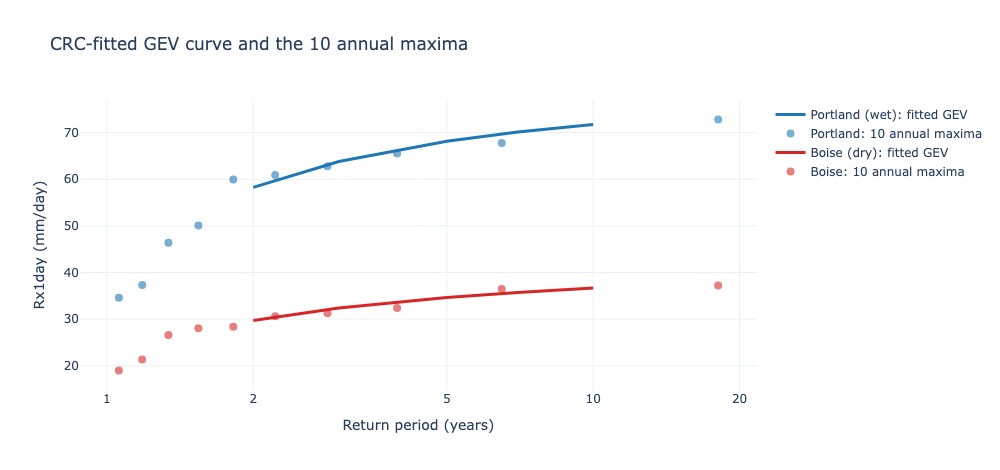

In [6]:
annual = plan.annual_extremes().to_pandas()  # year, latitude, longitude, value
cells = annual[["latitude", "longitude"]].drop_duplicates().to_numpy()


def nearest_cell(lon, lat):
    distance = (cells[:, 0] - lat) ** 2 + ((cells[:, 1] - lon) * np.cos(np.radians(lat))) ** 2
    return tuple(cells[distance.argmin()])


CURVE_RPS = [2, 3, 5, 7, 10]
SHOWN = {"Portland": "#1f77b4", "Boise": "#d62728"}
nearest = {name: nearest_cell(*CITIES[name]) for name in SHOWN}
curve_assets = pa.table({
    "asset_id": list(nearest),
    "longitude": [lon for _, lon in nearest.values()],
    "latitude": [lat for lat, _ in nearest.values()],
})
curve_path = DATA_DIR / "cmip6_pnw_rx1day_curves.parquet"
rx.for_assets(curve_assets).return_periods(CURVE_RPS).write_parquet(curve_path)
curves = pq.read_table(curve_path).to_pandas().set_index("asset_id")

fig_curves = go.Figure()
for name, color in SHOWN.items():
    cell_lat, cell_lon = nearest[name]
    series = annual[(annual["latitude"] == cell_lat) & (annual["longitude"] == cell_lon)]
    periods, values = plotting_position_curve(series["value"].to_numpy(), "upper")
    fig_curves.add_trace(go.Scatter(
        x=CURVE_RPS, y=[curves.loc[name, f"value_rp{rp}"] for rp in CURVE_RPS],
        mode="lines", line=dict(color=color, width=3),
        name=f"{name} ({'wet' if name == 'Portland' else 'dry'}): fitted GEV"))
    fig_curves.add_trace(go.Scatter(
        x=periods, y=values, mode="markers", marker=dict(color=color, size=8, opacity=0.6),
        name=f"{name}: {len(series)} annual maxima"))
fig_curves.update_layout(
    title="CRC-fitted GEV curve and the 10 annual maxima",
    xaxis=dict(title="Return period (years)", type="log", tickvals=[1, 2, 5, 10, 20],
               ticktext=["1", "2", "5", "10", "20"]),
    yaxis_title="Rx1day (mm/day)",
)
fig_curves.show()


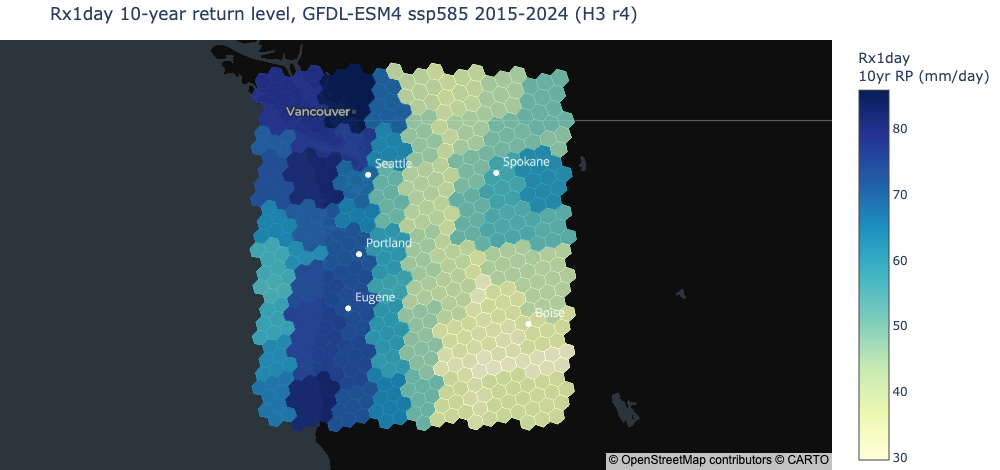

Years most often wettest across the cells: {2024: 17, 2019: 14, 2020: 12, 2015: 11}


In [7]:
probability = return_periods_to_probabilities([10], tail=meta.return_period_tail)[0]
canonical = read_hazard_dataset(rx.provider.source)
level_10 = pd.DataFrame({
    "cell": canonical["cell_index"].to_pylist(),
    "rx1day_10yr": curve_quantiles_at(canonical, probability),
}).groupby("cell", as_index=False).max()

hex_geojson = {
    "type": "FeatureCollection",
    "features": [
        {"type": "Feature", "id": str(cell), "geometry": mapping(cell_polygon(cell))}
        for cell in level_10["cell"]
    ],
}
fig_map = go.Figure(go.Choroplethmap(
    geojson=hex_geojson, locations=level_10["cell"].astype(str), z=level_10["rx1day_10yr"],
    colorscale="YlGnBu", marker_line_width=0, marker_opacity=0.85,
    colorbar_title="Rx1day<br>10yr RP (mm/day)",
))
fig_map.add_trace(go.Scattermap(
    lon=[lon for lon, _ in CITIES.values()], lat=[lat for _, lat in CITIES.values()],
    mode="markers+text", text=list(CITIES), textposition="top right",
    marker=dict(size=7, color="white"), textfont=dict(color="white"), showlegend=False,
))
fig_map.update_layout(
    map_style="carto-darkmatter", map_zoom=4.2,
    map_center={"lat": (BOUNDS[1] + BOUNDS[3]) / 2, "lon": (BOUNDS[0] + BOUNDS[2]) / 2},
    margin=dict(l=0, r=0, t=40, b=0),
    title=f"Rx1day 10-year return level, {MODEL} {SCENARIO} {YEARS[0]}-{YEARS[1]} (H3 r{H3_RES})",
)
fig_map.show()

hottest = annual.loc[annual.groupby(["latitude", "longitude"])["value"].idxmax(), "year"]
print("Years most often wettest across the cells:",
      {int(y): int(c) for y, c in hottest.value_counts().head(4).items()})


## How to read this, and its limits

- **One model, one member, one scenario.** This is a single CMIP6 realisation of
  `ssp585`, not an ensemble; `ensemble.pooling` records `single_member`. A real
  baseline pools members and models, and the spread between them is itself the
  signal.
- **Ten years is a very short record.** Ten annual maxima barely constrain a
  three-parameter GEV, so the shape is uncertain and levels beyond ~10 years are
  extrapolation; the file's `return_period_support` bounds it. Widen `YEARS` for
  a real fit.
- **A coarse model grid smears terrain.** At ~1 degree a cell is a large area
  average, so a city's value is regional and the rain shadow is softened.
  Rx1day from a climate model also underestimates convective extremes.
- **Projection, not observation.** CMIP6 is a model world; use it for *change*
  signals (compare `historical` with a scenario, or decades within one) rather
  than as a design storm.
- **Provenance travels with the file.** Licence, attribution, source URI, window
  and ensemble are in the Parquet metadata, as for every other source.

## Scaling this up

Change `MODEL`, `SCENARIO`, `YEARS` or `BOUNDS`, or raise `H3_RES` for a finer
canonical grid. The recipe name selects the indicator: `txx`, `tnn`, `rx1day` and
`rx5day` use the same definitions as ERA5, so a `historical` run and a scenario
can be differenced. The natural next step is the **historical vs ssp585 delta**:
build both and subtract the return levels, joining on `(hazard_name, horizon,
pathway, cell_index)`, to get a near-term change map. A source with no recipe can
still be canonicalized from per-cell annual samples; see the SDK's
[bring-your-own-data guide](https://github.com/RiskThinking/crc-sdk/blob/main/docs/bring-your-own-data.md).
